In [1]:
import os, re, sys, platform, pathlib
EXCLUDE_DIRS = [
    "apps/extension",
]
WORKSPACE    = pathlib.Path.cwd()
PROJECTS_DIR = WORKSPACE / "projects"
TOOLS_DIR    = WORKSPACE / ".tools"
TOKEN_FILE   = WORKSPACE / ".sonar-token"      # generated token is cached here
REPO_URL    = "https://github.com/ImgyeongLee/Aida-starter-template.git"
REPO_BRANCH = "r2-0901"     # None = the repo's default branch
REPO_BRANCHES = ["main","r1-0901", "r2-0901", "r3-0901", "r4-0901"]  # for multi-branch analysis
CLONE_DEPTH = 1             # shallow clone; set to None for full history

REPO_NAME = re.sub(r"\.git$", "", REPO_URL.rstrip("/").split("/")[-1])
REPO_DIR  = PROJECTS_DIR / REPO_NAME
_key_base = REPO_NAME
SEPARATE_PROJECT_PER_BRANCH = True
if SEPARATE_PROJECT_PER_BRANCH and REPO_BRANCH:
    _key_base = f"{REPO_NAME}--{REPO_BRANCH}"
PROJECT_KEY  = re.sub(r"[^A-Za-z0-9_.\-]", "-", _key_base)


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Saved call graph: e:\RepositoryStaticAnalysis\call_graphs\Aida-starter-template--r2-0901.graphml
Nodes (functions): 88
Edges (caller -> callee): 57
Median fan-in: 0.0
Mean fan-in: 0.6477272727272727
Max fan-in: 13
Min fan-in: 0


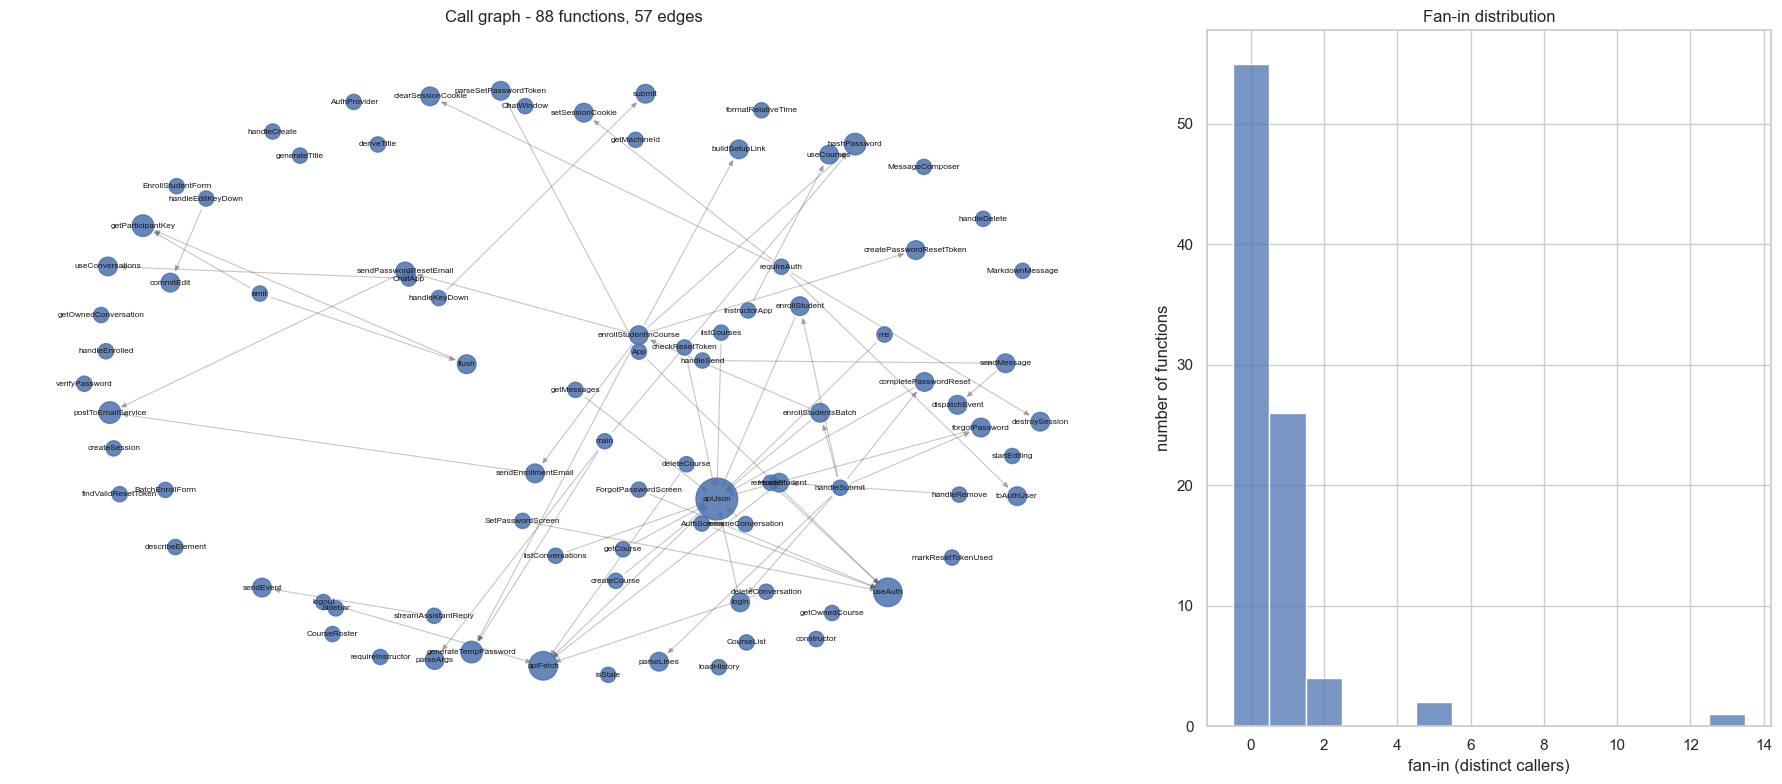

In [2]:
# custom tree sitter tool
%pip install -q tree-sitter tree-sitter-language-pack networkx

import statistics
from tree_sitter_language_pack import get_parser
import networkx as nx

# extension to tree-sitter-language-pack grammar name
EXT_TO_LANG = {
    "py": "python",
    "js": "javascript", "jsx": "javascript", "mjs": "javascript", "cjs": "javascript",
    "ts": "typescript", "tsx": "tsx",
    "java": "java",
    "go": "go",
    "rb": "ruby",
    "c": "c", "h": "c",
    "cpp": "cpp", "cc": "cpp", "cxx": "cpp", "hpp": "cpp",
    "cs": "c_sharp",
    "php": "php",
    "rs": "rust",
}

# node types that introduce a function/method across the grammars above
FUNCTION_NODE_TYPES = {
    "function_definition", "function_declaration", "method_definition",
    "function_item", "method_declaration", "arrow_function", "function_expression",
}
# node types that represent a call across the grammars above (python uses "call",
# most C-family/JS/Java grammars use "call_expression", Java also "method_invocation")
CALL_NODE_TYPES = {"call", "call_expression", "method_invocation"}

# generic build/vendor noise to skip everywhere
_SKIP_DIR_NAMES = {
    "node_modules", "dist", "build", "out", "target", "vendor",
    ".venv", "venv", "__pycache__", ".git",
}
# repo-specific dirs from cell 1 (e.g. "apps/extension") - these are relative
# paths, not single directory names, so they're matched separately below
_SKIP_REL_DIRS = [d.strip("/") for d in EXCLUDE_DIRS]

_parsers = {}
def _get_parser(lang_name):
    if lang_name not in _parsers:
        _parsers[lang_name] = get_parser(lang_name)
    return _parsers[lang_name]

def _walk(node):
    """Yield node and every descendant (children-only iteration misses nested
    defs/calls, since real code nests them inside class/if/block nodes)."""
    yield node
    for child in node.children:
        yield from _walk(child)

def _function_name(node):
    name_node = node.child_by_field_name("name")
    if name_node is not None:
        return name_node.text.decode("utf-8", "replace")
    # arrow/anonymous functions have no "name" field of their own - the name
    # lives on the enclosing binding, e.g. `const foo = () => {...}`
    parent = node.parent
    if parent is not None and parent.type in ("variable_declarator", "assignment_expression"):
        target = parent.child_by_field_name("name") or parent.child_by_field_name("left")
        if target is not None:
            return target.text.decode("utf-8", "replace")
    return None

def _enclosing_function_name(node):
    """Walk up from a call node to the nearest function/method it's defined in.
    Calls at module/top level (not inside any function) have no caller name."""
    n = node.parent
    while n is not None:
        if n.type in FUNCTION_NODE_TYPES:
            return _function_name(n)
        n = n.parent
    return None

def _callee_name(call_node):
    fn = call_node.child_by_field_name("function")
    if fn is None:
        return None
    if not fn.children:
        return fn.text.decode("utf-8", "replace")
    # member/attribute expression (obj.method(), this.method()) - best-effort
    # match on just the rightmost name, since resolving the receiver's type
    # would need real type info
    for field in ("property", "attribute", "name"):
        sub = fn.child_by_field_name(field)
        if sub is not None:
            return sub.text.decode("utf-8", "replace")
    return None

def _is_excluded(file):
    if any(part in _SKIP_DIR_NAMES for part in file.parts):
        return True
    rel_parts = file.relative_to(REPO_DIR).parts
    for rel_dir in _SKIP_REL_DIRS:
        rel_dir_parts = tuple(rel_dir.split("/"))
        if rel_parts[:len(rel_dir_parts)] == rel_dir_parts:
            return True
    return False

source_files = [
    f for f in REPO_DIR.rglob("*.*")
    if not _is_excluded(f) and f.suffix.lstrip(".") in EXT_TO_LANG
]

trees = []
for file in source_files:
    lang_name = EXT_TO_LANG[file.suffix.lstrip(".")]
    try:
        parser = _get_parser(lang_name)
        with open(file, "rb") as f:
            code = f.read()
        trees.append(parser.parse(code))
    except Exception as e:
        print(f"skip {file}: {e}")

# pass 1: register every function/method name. Each callee maps to the list of
# names of the functions that call it - this is what gets turned into the graph.
functions = {}
for tree in trees:
    for node in _walk(tree.root_node):
        if node.type in FUNCTION_NODE_TYPES:
            name = _function_name(node)
            if name:
                functions.setdefault(name, [])

# pass 2: for every call site, record which enclosing function made the call.
# two passes are needed so forward references and cross-file calls resolve -
# a single pass drops calls to functions the scanner hasn't reached yet.
for tree in trees:
    for node in _walk(tree.root_node):
        if node.type in CALL_NODE_TYPES:
            callee = _callee_name(node)
            if callee in functions:
                caller = _enclosing_function_name(node)
                if caller is not None:
                    functions[callee].append(caller)

# build the actual call graph: one directed edge per (caller, callee) pair,
# pointing at the callee. Repeated calls between the same pair collapse into
# one edge here (fan-in = number of DISTINCT callers, not total call sites) -
# that's the number that answers "how many other functions are affected".
G = nx.DiGraph()
G.add_nodes_from(functions.keys())
for callee, callers in functions.items():
    for caller in callers:
        G.add_edge(caller, callee)

GRAPH_DIR = WORKSPACE / "call_graphs"
GRAPH_DIR.mkdir(exist_ok=True)
graph_path = GRAPH_DIR / f"{PROJECT_KEY}.graphml"
nx.write_graphml(G, graph_path)

in_degrees = [d for _, d in G.in_degree()]

print(f"Saved call graph: {graph_path}")
print(f"Nodes (functions): {G.number_of_nodes()}")
print(f"Edges (caller -> callee): {G.number_of_edges()}")
print(f"Median fan-in: {statistics.median(in_degrees)}")
print(f"Mean fan-in: {statistics.mean(in_degrees)}")
print(f"Max fan-in: {max(in_degrees)}")
print(f"Min fan-in: {min(in_degrees)}")

# --- visualize -------------------------------------------------------------
# seaborn has no node/edge plot type - the diagram itself comes from
# networkx+matplotlib; seaborn just styles it and draws the fan-in histogram.
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, (ax_graph, ax_hist) = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [2, 1]})

pos = nx.spring_layout(G, k=0.5, seed=42)
node_sizes = [120 + 60 * G.in_degree(n) for n in G.nodes()]
nx.draw_networkx_edges(G, pos, alpha=0.25, arrows=True, arrowsize=8, width=0.8, ax=ax_graph)
nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color="#4C72B0", alpha=0.85, ax=ax_graph)
nx.draw_networkx_labels(G, pos, font_size=6, ax=ax_graph)
ax_graph.set_title(f"Call graph - {G.number_of_nodes()} functions, {G.number_of_edges()} edges")
ax_graph.axis("off")

sns.histplot(in_degrees, discrete=True, color="#4C72B0", ax=ax_hist)
ax_hist.set_xlabel("fan-in (distinct callers)")
ax_hist.set_ylabel("number of functions")
ax_hist.set_title("Fan-in distribution")

plt.tight_layout()
plt.show()